In [2]:
import pandas as pd
import pickle
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
import shap
import numpy as np
import pandas as pd
import os

In [3]:

datafile = "Dataset_14_features.xlsx"

df = pd.read_excel(datafile)

with open('14_feat_NGB_model.pkl', 'rb') as file:
    NGB_model = pickle.load(file)

X = df.drop(['Formulation_number', 'Modification','Drug', 'Cross_linker', 'DL'], axis='columns')
y = df['DL']

In [4]:
stdScale = StandardScaler().fit(X)
X_scale = stdScale.transform(X)

In [5]:
NGB_model

NGBRegressor(Base=DecisionTreeRegressor(max_depth=16), col_sample=0.8,
             learning_rate=0.1, minibatch_frac=0.8, n_estimators=100,
             random_state=RandomState(MT19937) at 0x1FAA40E5940)

In [6]:
bestModel = NGB_model
bestModel.fit(X, y)
explainer = shap.TreeExplainer(NGB_model)
shap_values = explainer(X)

[iter 0] loss=4.3042 val_loss=0.0000 scale=2.0000 norm=29.3670


c:\Users\Afra\AppData\Local\Programs\Python\Python39\lib\site-packages\shap\explainers\_tree.py:1403: UserWarning: Translating model_output="raw" to model_output=0 for the 0-th parameter in the distribution. Use model_output=0 directly to avoid this warning.
  warnings.warn(


In [7]:
shap_values

.values =
array([[  0.75597034,  -7.55493803,   0.55029982, ...,  -3.7648563 ,
         -1.55457301,  -1.88277357],
       [  0.60185885,  -7.21718811,   0.69845066, ...,  -1.91657989,
         -1.4109319 ,  -1.65367419],
       [ -0.23572592,  -6.49042113,   0.36484474, ...,   0.37890405,
         -2.9053879 ,  -2.07270922],
       ...,
       [ -1.94748428,  -1.71602275,   0.28823598, ...,   4.29899229,
          1.38062926,   2.59918691],
       [  1.44866961,   1.16943095,   0.43278639, ...,   4.77304004,
          0.26522762,  -0.98044602],
       [ -0.16323886, -11.74545076,   0.33609394, ...,   2.99319416,
         -0.35294349,  -3.31823378]])

.base_values =
array([24.62005502, 24.62005502, 24.62005502, 24.62005502, 24.62005502,
       24.62005502, 24.62005502, 24.62005502, 24.62005502, 24.62005502,
       24.62005502, 24.62005502, 24.62005502, 24.62005502, 24.62005502,
       24.62005502, 24.62005502, 24.62005502, 24.62005502, 24.62005502,
       24.62005502, 24.62005502, 24.6

In [8]:
shap_values_dataframe = pd.DataFrame(shap_values.values, columns=X.columns)

In [9]:
X.head()

,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,NumHDonors,MolLogP
0,0.07,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,489.3,6,0.4231
1,0.10,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,342.2,6,0.4231
2,0.17,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,209.6,6,0.4231
3,0.25,10.00,1,2,0.0,0.0,0.0,250000.00,4.50,1449.25,2.99,194.7,19,0.1062
4,0.25,10.00,1,2,0.0,0.0,0.0,140000.00,3.60,1449.25,2.99,350.1,19,0.1062


In [10]:
shap_values_dataframe.head()

,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,NumHDonors,MolLogP
0,0.755970,-7.554938,0.550300,0.406664,-0.057767,-0.207471,-0.822572,0.036891,-0.061257,2.657296,-0.720968,-3.764856,-1.554573,-1.882774
1,0.601859,-7.217188,0.698451,0.248167,-0.040373,-0.185844,-0.661610,0.029748,-0.038803,2.894100,-0.667376,-1.916580,-1.410932,-1.653674
2,-0.235726,-6.490421,0.364845,-0.323850,-0.065502,-0.096389,-0.228162,0.535409,-0.021664,2.176250,-0.735653,0.378904,-2.905388,-2.072709
3,-0.855317,11.591781,1.155758,0.510914,0.060940,-0.025484,-0.440004,1.283199,0.886612,6.830078,3.242941,0.229535,1.560641,1.348351
4,-0.669806,12.432357,1.457603,0.568374,0.059448,-0.070489,-0.506792,1.179694,1.007072,7.672932,3.235715,-2.314017,1.668537,1.459318


In [11]:
shap_values_dataframe

,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,NumHDonors,MolLogP
0,0.755970,-7.554938,0.550300,0.406664,-0.057767,-0.207471,-0.822572,0.036891,-0.061257,2.657296,-0.720968,-3.764856,-1.554573,-1.882774
1,0.601859,-7.217188,0.698451,0.248167,-0.040373,-0.185844,-0.661610,0.029748,-0.038803,2.894100,-0.667376,-1.916580,-1.410932,-1.653674
2,-0.235726,-6.490421,0.364845,-0.323850,-0.065502,-0.096389,-0.228162,0.535409,-0.021664,2.176250,-0.735653,0.378904,-2.905388,-2.072709
3,-0.855317,11.591781,1.155758,0.510914,0.060940,-0.025484,-0.440004,1.283199,0.886612,6.830078,3.242941,0.229535,1.560641,1.348351
4,-0.669806,12.432357,1.457603,0.568374,0.059448,-0.070489,-0.506792,1.179694,1.007072,7.672932,3.235715,-2.314017,1.668537,1.459318
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
136,5.872564,25.583722,0.292170,-0.107069,0.286977,0.288057,12.841397,0.020719,-0.039933,5.981831,-0.691627,1.888950,2.474358,3.137829
137,-1.678695,-5.854200,0.272005,-0.218342,-0.903256,0.193095,-0.189942,0.334410,-0.039794,-3.312344,0.718673,3.528961,0.489094,-1.409720
138,-1.947484,-1.716023,0.288236,-0.145935,-1.386925,1.100640,-0.357634,0.376351,0.006313,-2.058273,1.741870,4.298992,1.380629,2.599187
139,1.448670,1.169431,0.432786,0.029181,0.028584,1.501455,0.664111,0.981599,-0.018498,3.212563,-0.127758,4.773040,0.265228,-0.980446


Global bar plot


In [12]:
os.makedirs("ArticleFigures", exist_ok=True)

# Create SHAP global bar plot without displaying it
ax = shap.plots.bar(
    shap_values,
    max_display=14,
    show=False
)

# Get the figure associated with the SHAP axes
fig = ax.figure

# PNG
fig.savefig(
    "ArticleFigures/Globalbarplot.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

# JPEG
fig.savefig(
    "ArticleFigures/Globalbarplot.jpg",
    dpi=600,
    bbox_inches="tight"
)

# JPEG
fig.savefig(
    "ArticleFigures/Globalbarplot.jpeg",
    dpi=600,
    bbox_inches="tight"
)

# TIFF
fig.savefig(
    "ArticleFigures/Globalbarplot.tiff",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

# PDF
fig.savefig(
    "ArticleFigures/Globalbarplot.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.close(fig)

beeswarm plot

In [13]:
os.makedirs("ArticleFigures", exist_ok=True)

ax = shap.plots.beeswarm(
    shap_values,
    max_display=14,
    show=False
)

fig = ax.figure

fig.savefig(
    "ArticleFigures/beeswarm1.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

fig.savefig(
    "ArticleFigures/beeswarm1.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

fig.savefig(
    "ArticleFigures/beeswarm1.tiff",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

fig.savefig(
    "ArticleFigures/beeswarm1.jpg",
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

decision_plot

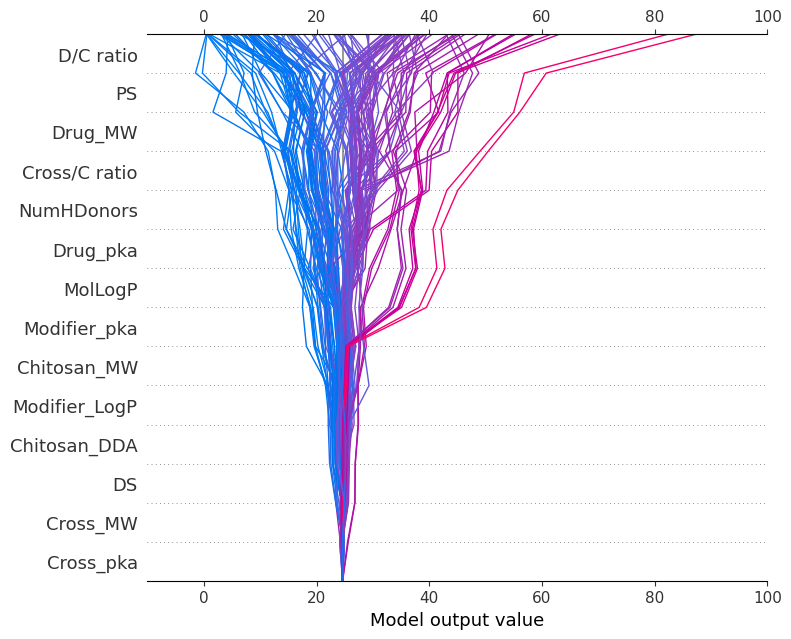

In [14]:
expected_value = explainer.expected_value
shap_values = explainer.shap_values(X)


shap.decision_plot(expected_value, shap_values, feature_names=X.columns.tolist(),
                   xlim=[-10, 100], show=False, color_bar=False)

plt.savefig('ArticleFigures/RF_Decision_plot.png',
            dpi=600, format='png', transparent=False)
plt.savefig('ArticleFigures/RF_Decision_plot.jpg', dpi=600, format = 'jpg', transparent=True, bbox_inches='tight')
plt.savefig('ArticleFigures/RF_Decision_plot.jpeg', dpi=600, format = 'jpeg', transparent=True, bbox_inches='tight')
plt.savefig('ArticleFigures/RF_Decision_plot.tiff', dpi=600, format = 'tiff', transparent=True, bbox_inches='tight')
plt.savefig('ArticleFigures/RF_Decision_plot.pdf', dpi=600, format = 'pdf', transparent=True, bbox_inches='tight')
plt.show()